# IndoBERTweet — Text-only

**Sebelum run:** pastikan `splits.csv` (hasil `00_make_splits.ipynb`) sudah ada di `DATA_DIR`.

Perubahan dari versi sebelumnya:
- Split train/val/test diambil dari `splits.csv` (berbasis `text_id`), sama untuk semua notebook → tidak ada leakage dan test set identik.
- Fitur polarisasi bisa dimatikan lewat `USE_POLARIZATION` (default `False`).
- Teks dipotong ke panjang yang sama (`TEXT_MAX_TOKENS`) di text-only maupun metadata.
- Stage 2: `weight_decay` sekarang dipakai; `class_weight_alpha` dihapus karena memang tidak berpengaruh.
- Final training bisa diulang beberapa seed (`FINAL_SEEDS`), dan prediksi test disimpan ke `preds_*.csv` untuk `99_compare.ipynb`.
- Nama study Optuna & file `.db` baru, supaya tidak memakai trial lama dari split yang bocor.


In [4]:
! pip install -q optuna
! pip install -q emoji
! pip install -q iterative-stratification

In [5]:
import pandas as pd
import numpy as np
import ast
import re
import gc
import os
import sys
import math
import shutil
import random
import matplotlib.pyplot as plt

import torch
from torch import nn
import datasets
from datasets import Dataset
import optuna
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix)
from scipy.special import softmax
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, EarlyStoppingCallback, TrainerCallback, set_seed)
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars

hf_logging.set_verbosity_error()          # laporan load model, warning transformers
hf_logging.disable_progress_bar()         # "Writing model shards", "Loading weights"
disable_progress_bars()                   # progress bar download dari Hugging Face Hub
datasets.disable_progress_bars()          # progress bar "Map"
optuna.logging.set_verbosity(optuna.logging.WARNING)   # log bawaan Optuna per trial

In [6]:
# ===================== KONFIGURASI =====================
MODEL_NAME = "indolem/indobertweet-base-uncased"
MODEL_TAG  = "indobertweet"
SETUP      = "text"            # "text" = text-only (majority vote), "meta" = teks + metadata annotator

# False = eksperimen utama tanpa fitur polarisasi (label polarisasi tidak tersedia saat deployment).
# True  = ablasi dengan polarisasi, supaya bisa dibandingkan dengan hasil lama.
USE_POLARIZATION = False

DATA_DIR       = "/kaggle/input/datasets/evelynuntariady/thesis"
OUT_DIR        = "/kaggle/working"
PREPROCESS_DIR = DATA_DIR                       # folder berisi preprocess.py
DATA_FILE      = f"{DATA_DIR}/data_thesis_full.csv"
SPLIT_FILE     = f"{DATA_DIR}/splits.csv"     # hasil 00_make_splits.ipynb

SEED          = 42
FINAL_SEEDS   = [42]        # disarankan [42, 43, 44] kalau waktu GPU cukup
N_TRIALS      = 10
N_TRIALS_S2   = 10
LOGGING_STEPS = 10
TEXT_MAX_TOKENS = 126       # panjang teks maks (token), sama untuk text-only & metadata

META_COLS = {}
META_TAG = ""
ID_COLS = ["text_id"]
DEMO_SAVE_COLS = []
LABEL_COLS = [
    "insults",
    "identity_attack",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit",
]

RUN_TAG = "_".join(x for x in [MODEL_TAG, SETUP, META_TAG, "pol" if USE_POLARIZATION else "nopol"] if x)
os.makedirs(OUT_DIR, exist_ok=True)
print("RUN_TAG:", RUN_TAG)

RUN_TAG: indobertweet_text_nopol


# Load & Prepare Data

In [7]:
df = pd.read_csv(DATA_FILE, dtype={"text_id": str})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27833 entries, 0 to 27832
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0                     27833 non-null  int64 
 1   text_id                        27833 non-null  object
 2   annotators_id                  27833 non-null  object
 3   text                           27832 non-null  object
 4   topic                          27833 non-null  object
 5   is_noise_or_spam_text          27833 non-null  object
 6   toxicity                       27833 non-null  object
 7   polarized                      27833 non-null  object
 8   profanity_obscenity            27833 non-null  object
 9   threat_incitement_to_violence  27833 non-null  object
 10  insults                        27833 non-null  object
 11  identity_attack                27833 non-null  object
 12  sexually_explicit              27833 non-null  object
 13  k

In [8]:
df_main = df.copy()

cols = [
    'is_noise_or_spam_text',
    'toxicity',
    'polarized',
    'profanity_obscenity',
    'threat_incitement_to_violence',
    'insults',
    'identity_attack',
    'sexually_explicit',
]
for col in cols:
    df_main[col] = df_main[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

vote_cols = [c for c in cols if c != 'polarized']

In [9]:
# Cek teks yang annotatornya seri (misal 1-1, 2-2). Seharusnya 0 setelah re-anotasi.
tie_report = {
    c: int(df_main[c].apply(lambda xs: np.mean([int(v) for v in xs]) == 0.5).sum())
    for c in vote_cols
}
print("Jumlah teks seri per kolom:", tie_report)

Jumlah teks seri per kolom: {'is_noise_or_spam_text': 168, 'toxicity': 945, 'profanity_obscenity': 216, 'threat_incitement_to_violence': 315, 'insults': 578, 'identity_attack': 513, 'sexually_explicit': 45}


In [10]:
# Majority vote. Hasilnya identik dengan round(mean) sebelumnya,
# tapi aturan seri ditulis eksplisit: seri -> 0.
def majority_vote(x):
    return int(np.mean([int(i) for i in x]) > 0.5)

for col in vote_cols:
    df_main[col] = df_main[col].apply(majority_vote)

df_main = df_main[df_main['is_noise_or_spam_text'] == 0]
df_main = df_main.dropna()

# Rata-rata polarisasi (hanya dipakai kalau USE_POLARIZATION = True)
df_main["pol_avg"] = df_main["polarized"].apply(lambda xs: float(np.mean([int(v) for v in xs])))
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26379 entries, 0 to 27832
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     26379 non-null  int64  
 1   text_id                        26379 non-null  object 
 2   annotators_id                  26379 non-null  object 
 3   text                           26379 non-null  object 
 4   topic                          26379 non-null  object 
 5   is_noise_or_spam_text          26379 non-null  int64  
 6   toxicity                       26379 non-null  int64  
 7   polarized                      26379 non-null  object 
 8   profanity_obscenity            26379 non-null  int64  
 9   threat_incitement_to_violence  26379 non-null  int64  
 10  insults                        26379 non-null  int64  
 11  identity_attack                26379 non-null  int64  
 12  sexually_explicit              26379 non-null  int6

# Text Cleaning

In [11]:
sys.path.append(PREPROCESS_DIR)   # folder yang berisi preprocess.py
from preprocess import preprocess_text
from tqdm import tqdm
tqdm.pandas()

SOURCE_COL = "cleaned_text"
df_main["processed_text"] = (
    df_main[SOURCE_COL].fillna("").astype(str).progress_apply(preprocess_text)
)
pd.set_option("display.max_colwidth", 150)
df_main[[SOURCE_COL, "processed_text"]].sample(5, random_state=42)

100%|██████████| 26379/26379 [00:06<00:00, 3922.45it/s]


,cleaned_text,processed_text
10146,INFO BOGOR: Pemakaman Tionghoa di Jonggol disegel akibat tak mengantongi izin. Foto: Penyegelan dilakukan oleh petugas Satpol PP di areal pemakama...,info bogor pemakaman tionghoa di jonggol disegel akibat tak mengantongi izin. foto penyegelan dilakukan oleh petugas satpol pp di areal pemakaman ...
454,Berikut ini adalah daftar pemain/pasangan yang WDN dari Victor China Open 2023!,berikut ini adalah daftar pemain pasangan yang wdn dari victor china open !
5488,"Saya coba terjemahkan: ""Jika ada orang berkata bahwa Thoriqoh Alawiyah tidak ada baiat, maka pembohonglah orang yang bilang begitu! Sesungguhnya T...","saya coba terjemahkan jika ada orang berkata bahwa thoriqoh alawiyah tidak ada baiat, maka pembohonglah orang yang bilang begitu! sesungguhnya tho..."
9465,"India, Pakistan, China tetap pasar potensial sawit RI","india, pakistan, china tetap pasar potensial sawit ri"
11901,"Mahfud MD dan kuburan China. Dengan segala kontroversinya, saya masih respek pada Prof. @mohmahfudmd, sosok yang ketika di Jogja dulu punya kebias...","mahfud md dan kuburan china. dengan segala kontroversinya, saya masih respek pada prof. , sosok yang ketika di jogja dulu punya kebiasaan belajar ..."


# Load Split (berbasis text_id)

In [12]:
# Split dibuat SEKALI di 00_make_splits.ipynb, berbasis text_id.
# Semua notebook (text-only & metadata, IndoBERTweet & NusaBERT) memakai file yang sama,
# jadi teks di test set identik dan tidak ada teks yang muncul di train sekaligus test.
splits = pd.read_csv(SPLIT_FILE, dtype={"text_id": str})
print(splits["s1_split"].value_counts(dropna=False))
print(splits["s2_split"].value_counts(dropna=False))

missing = set(splits["text_id"]) - set(df_main["text_id"])
print(f"text_id di splits.csv yang tidak ada di data ini: {len(missing)}")

s1_split
train    6716
test     1920
val       960
Name: count, dtype: int64
s2_split
NaN      7197
train    1679
test      480
val       240
Name: count, dtype: int64
text_id di splits.csv yang tidak ada di data ini: 0


# Input Encoding

In [13]:
# Prefix yang ditempel sebelum teks ([CLS] prefix [SEP] teks [SEP]).
# - text-only : None (atau rata-rata polarisasi kalau USE_POLARIZATION)
# - metadata  : demografi annotator sesuai META_COLS (+ polarisasi annotator kalau USE_POLARIZATION)
def build_prefix(frame, stage):
    if SETUP == "text":
        if USE_POLARIZATION and stage == 1:
            return [f"Nilai rata-rata polarisasi: {v:.2f}" for v in frame["pol_avg"]]
        return None

    pieces = []
    if USE_POLARIZATION and stage == 1:
        pieces.append(frame["polarized"].astype(str).radd("Polarisasi: ") + ".")
    for col, name in META_COLS.items():
        pieces.append(frame[col].astype(str).radd(f"{name}: ") + ".")
    if not pieces:
        return None
    return [" ".join(p) for p in zip(*pieces)]

In [14]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
CLS_ID, SEP_ID, PAD_ID = tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id


def encode(texts, prefixes=None):
    """Teks selalu dipotong ke TEXT_MAX_TOKENS token, baik text-only maupun metadata,
    supaya kedua setup melihat potongan teks yang sama panjang. Prefix tidak dipotong."""
    text_ids = tokenizer(list(texts), add_special_tokens=False, truncation=True,
                         max_length=TEXT_MAX_TOKENS)["input_ids"]
    if prefixes is None:
        seqs = [[CLS_ID] + t + [SEP_ID] for t in text_ids]
        types = [[0] * len(s) for s in seqs]
    else:
        pre_ids = tokenizer(list(prefixes), add_special_tokens=False)["input_ids"]
        seqs, types = [], []
        for p, t in zip(pre_ids, text_ids):
            a, b = [CLS_ID] + p + [SEP_ID], t + [SEP_ID]
            seqs.append(a + b)
            types.append([0] * len(a) + [1] * len(b))
    return seqs, types


def to_dataset(seqs, types, labels, max_len):
    ids  = [s + [PAD_ID] * (max_len - len(s)) for s in seqs]
    mask = [[1] * len(s) + [0] * (max_len - len(s)) for s in seqs]
    tt   = [t + [0] * (max_len - len(t)) for t in types]
    ds = Dataset.from_dict({"input_ids": ids, "attention_mask": mask,
                            "token_type_ids": tt, "labels": labels})
    ds.set_format("torch")
    return ds


def build_datasets(frames, stage, label_fn):
    encoded = [encode(f["processed_text"], build_prefix(f, stage)) for f in frames]
    max_len = max(len(s) for seqs, _ in encoded for s in seqs)
    assert max_len <= 512, f"Input terlalu panjang ({max_len} token)"
    out = [to_dataset(seqs, types, label_fn(f), max_len) for (seqs, types), f in zip(encoded, frames)]
    print(f"Stage {stage} max_len = {max_len}")
    print("Contoh input:", tokenizer.decode(out[0][0]["input_ids"], skip_special_tokens=False)[:400])
    return out

In [15]:
def freeze_layer(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder."""
    base = model.base_model
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False


class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def common_search_space(trial):
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 8e-6, 6e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr_scheduler_type": trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        # Prioritas rendah
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 0, 6),
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [False, True]),
    }


def make_training_args(params, out_dir, n_train, seed, metric):
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(n_train / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])
    return TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        weight_decay=params["weight_decay"],
        lr_scheduler_type=params["lr_scheduler_type"],
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model=metric,
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,
        report_to=[],
        seed=seed,
    )


def cleanup(trainer=None, out_dir=None):
    del trainer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if out_dir:
        shutil.rmtree(out_dir, ignore_errors=True)


def plot_loss(trainer, title):
    history = trainer.state.log_history
    train_logs = [x for x in history if 'loss' in x and 'eval_loss' not in x]
    epochs = [x['epoch'] for x in train_logs]
    losses = [x['loss'] for x in train_logs]
    ep_nums = sorted(set(int(np.ceil(e)) for e in epochs))
    avg_train = [np.mean([l for e, l in zip(epochs, losses) if int(np.ceil(e)) == ep]) for ep in ep_nums]
    val = {}
    for x in history:
        if 'eval_loss' in x:
            ep = int(round(x['epoch']))
            if ep > 0 and ep not in val:
                val[ep] = x['eval_loss']
    plt.figure(figsize=(10, 6))
    plt.plot(ep_nums, avg_train, marker='o', label='Training Loss')
    plt.plot(sorted(val), [val[e] for e in sorted(val)], marker='o', label='Validation Loss')
    plt.title(title)
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

# Stage 1 — Toxic vs Non-Toxic

In [16]:
df_s1 = df_main.merge(splits[["text_id", "s1_split"]].dropna(), on="text_id", how="inner")
df_s1 = df_s1.rename(columns={"toxicity": "label"})

train_s1 = df_s1[df_s1["s1_split"] == "train"].reset_index(drop=True)
val_s1   = df_s1[df_s1["s1_split"] == "val"].reset_index(drop=True)
test_s1  = df_s1[df_s1["s1_split"] == "test"].reset_index(drop=True)

print("Stage 1 split sizes:", {"train": len(train_s1), "val": len(val_s1), "test": len(test_s1)})
print("Teks unik per split:", {s: d["text_id"].nunique() for s, d in
                               [("train", train_s1), ("val", val_s1), ("test", test_s1)]})
print(train_s1["label"].value_counts())

# Sanity check leakage: tidak boleh ada text_id yang sama di train dan test
assert not (set(train_s1.text_id) & set(test_s1.text_id)), "LEAKAGE: teks yang sama ada di train & test"
assert not (set(train_s1.text_id) & set(val_s1.text_id)), "LEAKAGE: teks yang sama ada di train & val"

Stage 1 split sizes: {'train': 6716, 'val': 960, 'test': 1920}
Teks unik per split: {'train': 6716, 'val': 960, 'test': 1920}
label
0    5037
1    1679
Name: count, dtype: int64


In [17]:
train_dataset_1, val_dataset_1, test_dataset_1 = build_datasets(
    [train_s1, val_s1, test_s1], stage=1, label_fn=lambda f: f["label"].astype(int).tolist()
)

class_weights_s1 = compute_class_weight(class_weight="balanced",
                                        classes=np.unique(train_s1["label"]), y=train_s1["label"])
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

Stage 1 max_len = 128
Contoh input: [CLS] kristen, hindu, islam dapat perlakuan istimewa dari pak anies ncep, ketar ketir [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [P
Stage 1 class weights (class 0, class 1): tensor([0.6667, 2.0000])


In [18]:
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    probs = softmax(logits, axis=1)[:, 1]
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
        "pr_auc": average_precision_score(labels, probs),
    }


# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [19]:
STUDY_NAME = f"s1_{RUN_TAG}_groupsplit_v1"   # nama baru: jangan pakai study lama (split bocor)
OUTPUT_ROOT = f"./optuna_s1_{RUN_TAG}"
FINAL_DIR = f"./best_s1_{RUN_TAG}"


def suggest_params(trial):
    params = common_search_space(trial)
    params["class_weight_alpha"] = trial.suggest_float("class_weight_alpha", 0.3, 1.0)
    return params


def build_trainer(params, out_dir, trial=None, seed=SEED):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0: "non_toxic", 1: "toxic"},
        label2id={"non_toxic": 0, "toxic": 1},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_layer(model, params["n_frozen_layers"], params["freeze_embeddings"])
    args = make_training_args(params, out_dir, len(train_dataset_1), seed, metric="f1")

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric="eval_f1"))

    return WeightedTrainerSingleLabel(
        model=model,
        args=args,
        train_dataset=train_dataset_1,
        eval_dataset=val_dataset_1,
        compute_metrics=compute_metrics_s1,
        class_weights=class_weights_s1 ** params["class_weight_alpha"],   # alpha=1 -> balanced penuh
        callbacks=callbacks,
    )


def objective_s1(trial):
    params = suggest_params(trial)
    out_dir = f"{OUTPUT_ROOT}/trial_{trial.number}"
    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")
    trainer = None
    try:
        trainer = build_trainer(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val F1 = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        cleanup(trainer, out_dir)

In [17]:
study_s1 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
    storage=f"sqlite:///optuna_s1_{RUN_TAG}.db",
    load_if_exists=True,
)
# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS
done = sum(t.state.is_finished() for t in study_s1.trials)
remaining = max(0, N_TRIALS - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s1.optimize(objective_s1, n_trials=remaining, gc_after_trial=True)

Trial selesai: 0 | sisa: 10

Trial 0
  learning_rate       : 1.70e-05
  warmup_ratio        : 0.19014286128198324
  batch_size          : 8
  num_train_epochs    : 3
  dropout             : 0.1116167224336399
  lr_scheduler_type   : linear
  weight_decay        : 0.07080725777960455
  n_frozen_layers     : 0
  freeze_embeddings   : False
  class_weight_alpha  : 0.44863737747479326


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.477785,0.440334,0.808333,0.602941,0.683333,0.640625,0.754972,0.868235,0.653329
2,0.298632,0.488634,0.779167,0.540462,0.779167,0.638225,0.739652,0.867043,0.659644
3,0.266979,0.508111,0.812500,0.604895,0.720833,0.657795,0.764335,0.870747,0.665829


Trial 0 selesai | best val F1 = 0.6578

Trial 1
  learning_rate       : 1.15e-05
  warmup_ratio        : 0.03668090197068676
  batch_size          : 16
  num_train_epochs    : 4
  dropout             : 0.22237057894447587
  lr_scheduler_type   : cosine
  weight_decay        : 0.03663618432936917
  n_frozen_layers     : 3
  freeze_embeddings   : False
  class_weight_alpha  : 0.6599641068895281


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.464212,0.476464,0.782292,0.547988,0.737500,0.628774,0.737379,0.850098,0.625262
2,0.398786,0.465354,0.795833,0.574324,0.708333,0.634328,0.746355,0.858009,0.642580
3,0.431822,0.469986,0.784375,0.550769,0.745833,0.633628,0.740430,0.861285,0.648763
4,0.390038,0.468080,0.786458,0.555205,0.733333,0.631957,0.740777,0.862199,0.649372


Trial 1 selesai | best val F1 = 0.6343

Trial 2
  learning_rate       : 2.64e-05
  warmup_ratio        : 0.009290082543999545
  batch_size          : 8
  num_train_epochs    : 8
  dropout             : 0.29312640661491185
  lr_scheduler_type   : linear
  weight_decay        : 0.009767211400638388
  n_frozen_layers     : 4
  freeze_embeddings   : False
  class_weight_alpha  : 0.6466238370778892


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.589693,0.466737,0.794792,0.564179,0.787500,0.657391,0.755461,0.861950,0.638054
2,0.409915,0.517189,0.753125,0.503632,0.866667,0.637060,0.725002,0.869358,0.656244
3,0.427863,0.496004,0.761458,0.513716,0.858333,0.642746,0.731850,0.869722,0.658166


... (11 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.446997,0.456792,0.811458,0.611321,0.675000,0.641584,0.756834,0.860880,0.642697
2,0.369092,0.551270,0.737500,0.486175,0.879167,0.626113,0.711933,0.868970,0.672244
3,0.362006,0.483001,0.784375,0.545706,0.820833,0.655574,0.749318,0.869022,0.678546
4,0.342513,0.489632,0.786458,0.548476,0.825000,0.658902,0.751741,0.869815,0.677356


Trial 8 selesai | best val F1 = 0.6589

Trial 9
  learning_rate       : 4.16e-05
  warmup_ratio        : 0.1721461166512687
  batch_size          : 16
  num_train_epochs    : 4
  dropout             : 0.12397307346673657
  lr_scheduler_type   : cosine
  weight_decay        : 0.03232029320207552
  n_frozen_layers     : 3
  freeze_embeddings   : False
  class_weight_alpha  : 0.9802474579046725


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.470575,0.485611,0.812500,0.611111,0.687500,0.647059,0.759700,0.866644,0.662464
2,0.315563,0.576035,0.712500,0.460870,0.883333,0.605714,0.689742,0.861209,0.661565
3,0.214463,0.591666,0.786458,0.554517,0.741667,0.634581,0.741867,0.859635,0.658757


Trial 9 selesai | best val F1 = 0.6471


In [18]:
print(f"Best trial #{study_s1.best_trial.number} | val F1 = {study_s1.best_value:.4f}")
for k, v in study_s1.best_params.items():
    print(f"  {k:20s}: {v}")
optuna.visualization.plot_param_importances(study_s1).show()
optuna.visualization.plot_optimization_history(study_s1).show()

Best trial #8 | val F1 = 0.6589
  learning_rate       : 5.207537298482086e-05
  warmup_ratio        : 0.1616240759128834
  batch_size          : 16
  num_train_epochs    : 4
  dropout             : 0.27851179969799555
  lr_scheduler_type   : cosine
  weight_decay        : 0.08960912999234932
  n_frozen_layers     : 2
  freeze_embeddings   : True
  class_weight_alpha  : 0.5989754520383794


In [22]:
best_params_s1 = {
  "learning_rate"       : 5.207537298482086e-05,
  "warmup_ratio"        : 0.1616240759128834,
  "batch_size"          : 16,
  "num_train_epochs"    : 4,
  "dropout"             : 0.27851179969799555,
  "lr_scheduler_type"   : "cosine",
  "weight_decay"        : 0.08960912999234932,
  "n_frozen_layers"     : 2,
  "freeze_embeddings"   : True,
  "class_weight_alpha"  : 0.5989754520383794
}


In [24]:
# Final training: best params dilatih ulang dengan tiap seed di FINAL_SEEDS.
# Prediksi test SEMUA seed disimpan ke CSV untuk dibandingkan di 99_compare.ipynb.
test_info_s1 = test_s1[ID_COLS + DEMO_SAVE_COLS + ["label"]].rename(columns={"label": "y_true"})

preds_s1_all = []
for i, seed in enumerate(FINAL_SEEDS):
    out_dir = f"{FINAL_DIR}_seed{seed}"
    trainer_s1 = build_trainer(best_params_s1, out_dir, seed=seed)
    trainer_s1.train()
    pred1 = trainer_s1.predict(test_dataset_1)
    probs = softmax(pred1.predictions.astype(np.float32), axis=1)[:, 1]

    out = test_info_s1.copy()
    out["seed"], out["prob"], out["pred"] = seed, probs, (probs >= 0.5).astype(int)
    preds_s1_all.append(out)
    print(f"seed {seed}: F1 toxic = {f1_score(out.y_true, out.pred):.4f} | "
          f"macro F1 = {f1_score(out.y_true, out.pred, average='macro'):.4f}")
    if i < len(FINAL_SEEDS) - 1:
        cleanup(trainer_s1, out_dir)

preds_s1 = pd.concat(preds_s1_all, ignore_index=True)
preds_s1.to_csv(f"{OUT_DIR}/preds_{RUN_TAG}_s1.csv", index=False)
print("Prediksi tersimpan:", f"{OUT_DIR}/preds_{RUN_TAG}_s1.csv")

# Model seed terakhir disimpan & dipakai untuk plot/report di bawah
trainer_s1.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
model_s1 = trainer_s1.model
y_test = test_info_s1["y_true"].values
probs1_test = probs
pred_label1 = (probs1_test >= 0.5).astype(int)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.446997,0.456792,0.811458,0.611321,0.675000,0.641584,0.756834,0.860880,0.642697
2,0.369092,0.551270,0.737500,0.486175,0.879167,0.626113,0.711933,0.868970,0.672244
3,0.362006,0.483001,0.784375,0.545706,0.820833,0.655574,0.749318,0.869022,0.678546
4,0.342513,0.489632,0.786458,0.548476,0.825000,0.658902,0.751741,0.869815,0.677356


seed 42: F1 toxic = 0.6774 | macro F1 = 0.7676
Prediksi tersimpan: /kaggle/working/preds_indobertweet_text_nopol_s1.csv


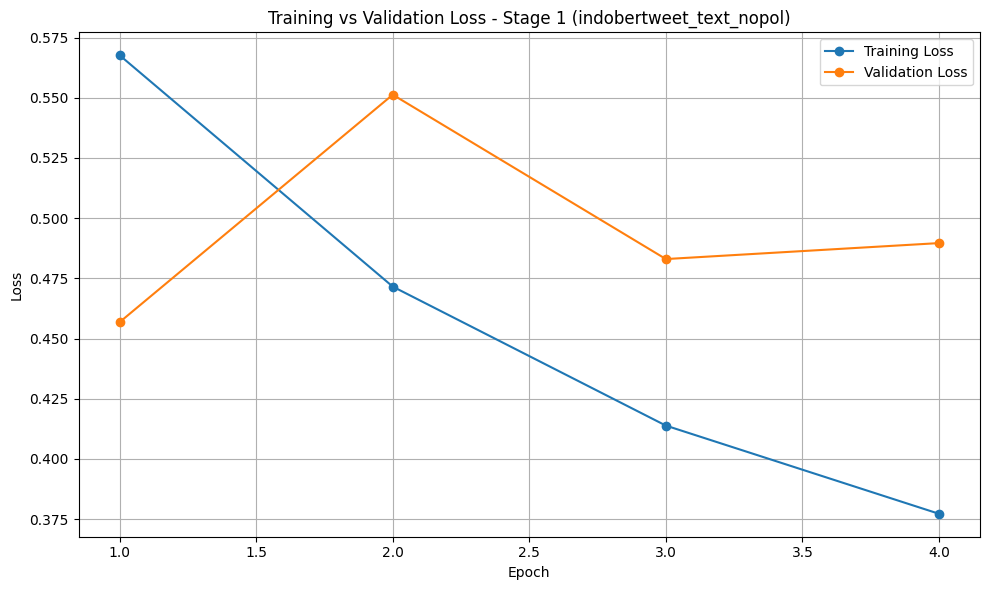

Stage 1 classification report -- test set (seed 42):
              precision    recall  f1-score   support

           0       0.93      0.79      0.86      1440
           1       0.57      0.83      0.68       480

    accuracy                           0.80      1920
   macro avg       0.75      0.81      0.77      1920
weighted avg       0.84      0.80      0.81      1920

ROC-AUC (test): 0.8829
PR-AUC  (test): 0.7217


,Predicted Non-Toxic (0),Predicted Toxic (1)
Actual Non-Toxic (0),1143,297
Actual Toxic (1),82,398


In [25]:
plot_loss(trainer_s1, f"Training vs Validation Loss - Stage 1 ({RUN_TAG})")

print(f"Stage 1 classification report -- test set (seed {FINAL_SEEDS[-1]}):")
print(classification_report(y_test, pred_label1))
print(f"ROC-AUC (test): {roc_auc_score(y_test, probs1_test):.4f}")
print(f"PR-AUC  (test): {average_precision_score(y_test, probs1_test):.4f}")

pd.DataFrame(confusion_matrix(y_test, pred_label1, labels=[0, 1]),
             index=["Actual Non-Toxic (0)", "Actual Toxic (1)"],
             columns=["Predicted Non-Toxic (0)", "Predicted Toxic (1)"])

# Stage 2 — Jenis Toksisitas (multi-label)

In [26]:
# Pool Stage 2: teks yang toxic secara majority (ditentukan di 00_make_splits.ipynb).
# text-only : 1 baris per teks, label jenis = majority vote
# metadata  : baris annotator yang menilai teks itu toxic, label jenis = label annotator tsb
df_s2 = df_main.merge(splits[["text_id", "s2_split"]].dropna(), on="text_id", how="inner")
df_s2 = df_s2[df_s2["toxicity"] == 1].reset_index(drop=True)

train_s2 = df_s2[df_s2["s2_split"] == "train"].reset_index(drop=True)
val_s2   = df_s2[df_s2["s2_split"] == "val"].reset_index(drop=True)
test_s2  = df_s2[df_s2["s2_split"] == "test"].reset_index(drop=True)

print("Stage 2 split sizes:", {"train": len(train_s2), "val": len(val_s2), "test": len(test_s2)})
print(pd.DataFrame({"train": train_s2[LABEL_COLS].sum(), "val": val_s2[LABEL_COLS].sum(),
                    "test": test_s2[LABEL_COLS].sum()}))
assert not (set(train_s2.text_id) & set(test_s2.text_id)), "LEAKAGE: teks yang sama ada di train & test"
assert not (set(train_s2.text_id) & set(val_s2.text_id)), "LEAKAGE: teks yang sama ada di train & val"

Stage 2 split sizes: {'train': 1679, 'val': 240, 'test': 480}
                               train  val  test
insults                          738  106   211
identity_attack                  696   99   199
threat_incitement_to_violence     75   11    22
profanity_obscenity              251   36    72
sexually_explicit                 43    6    12


In [27]:
# Random oversampling of minority-label rows for Stage 2 (multi-label). Only the TRAIN
# split is resampled -- val/test keep their natural distribution.
def oversample_multilabel(df, label_cols, random_state=42):
    max_count = df[label_cols].sum().max()
    parts = [df]
    for col in label_cols:
        n_needed = int(max_count - df[col].sum())
        if n_needed > 0:
            minority_rows = df[df[col] == 1]
            if len(minority_rows) > 0:
                parts.append(minority_rows.sample(n=n_needed, replace=True, random_state=random_state))
    return pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)


print("Before oversampling:", {c: int(train_s2[c].sum()) for c in LABEL_COLS})
train_s2_os = oversample_multilabel(train_s2, LABEL_COLS, random_state=42)
print("After oversampling:", {c: int(train_s2_os[c].sum()) for c in LABEL_COLS})

Before oversampling: {'insults': 738, 'identity_attack': 696, 'threat_incitement_to_violence': 75, 'profanity_obscenity': 251, 'sexually_explicit': 43}
After oversampling: {'insults': 1074, 'identity_attack': 1145, 'threat_incitement_to_violence': 747, 'profanity_obscenity': 977, 'sexually_explicit': 759}


In [28]:
train_dataset_2, val_dataset_2, test_dataset_2 = build_datasets(
    [train_s2_os, val_s2, test_s2], stage=2,
    label_fn=lambda f: f[LABEL_COLS].astype(float).values.tolist()   # float: BCEWithLogitsLoss
)

Stage 2 max_len = 128
Contoh input: [CLS] isu prabowo cekik wamentan, gerindra ungkap nasdem penyebar awalnya. rabu siang tante lina, mata najwa, t, malang, terbuka. mba nana, ganjar paling solutif. indomy for yoongi. kirgistan, jurnalis, bacapres bicara gagasan hugo, samir, tka china, felix, who, in riize [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [P


In [29]:
def safe_auc(score_fn, labels, probs):
    """AUC macro; NaN kalau ada label yang di split ini cuma punya satu kelas."""
    try:
        return score_fn(labels, probs, average="macro")
    except ValueError:
        return float("nan")


def compute_metrics_s2(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(labels, preds),   # exact match (subset accuracy)
        "precision_micro": precision_score(labels, preds, average="micro", zero_division=0),
        "recall_micro": recall_score(labels, preds, average="micro", zero_division=0),
        "f1_micro": f1_score(labels, preds, average="micro", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": safe_auc(roc_auc_score, labels, probs),
        "pr_auc": safe_auc(average_precision_score, labels, probs),
    }

In [30]:
STUDY_NAME_S2 = f"s2_{RUN_TAG}_groupsplit_v1"
OUTPUT_ROOT_S2 = f"./optuna_s2_{RUN_TAG}"
FINAL_DIR_S2 = f"./best_s2_{RUN_TAG}"
METRIC_S2 = "f1_macro"   # macro: setiap label (termasuk yang langka) berbobot sama


def suggest_params_s2(trial):
    # class_weight_alpha dihapus: Stage 2 tidak memakai class weight
    # (imbalance ditangani oversampling), jadi parameter itu tidak berpengaruh.
    return common_search_space(trial)


def build_trainer_s2(params, out_dir, trial=None, seed=SEED):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(LABEL_COLS),
        problem_type="multi_label_classification",
        id2label={i: l for i, l in enumerate(LABEL_COLS)},
        label2id={l: i for i, l in enumerate(LABEL_COLS)},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_layer(model, params["n_frozen_layers"], params["freeze_embeddings"])
    # weight_decay sekarang ikut dipakai (sebelumnya lupa)
    args = make_training_args(params, out_dir, len(train_dataset_2), seed, metric=METRIC_S2)

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric=f"eval_{METRIC_S2}"))

    return Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset_2,
        eval_dataset=val_dataset_2,
        compute_metrics=compute_metrics_s2,
        callbacks=callbacks,
    )


def objective_s2(trial):
    params = suggest_params_s2(trial)
    out_dir = f"{OUTPUT_ROOT_S2}/trial_{trial.number}"
    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")
    trainer = None
    try:
        trainer = build_trainer_s2(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val {METRIC_S2} = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        cleanup(trainer, out_dir)

In [26]:
study_s2 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME_S2,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
    storage=f"sqlite:///optuna_s2_{RUN_TAG}.db",
    load_if_exists=True,
)
done = sum(t.state.is_finished() for t in study_s2.trials)
remaining = max(0, N_TRIALS_S2 - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s2.optimize(objective_s2, n_trials=remaining, gc_after_trial=True)

Trial selesai: 0 | sisa: 10

Trial 0
  learning_rate       : 1.70e-05
  warmup_ratio        : 0.19014286128198324
  batch_size          : 8
  num_train_epochs    : 3
  dropout             : 0.1116167224336399
  lr_scheduler_type   : linear
  weight_decay        : 0.07080725777960455
  n_frozen_layers     : 0
  freeze_embeddings   : False


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.717037,0.763552,0.350000,0.619792,0.461240,0.528889,0.536868,0.789689,0.585849
2,0.485280,0.703684,0.383333,0.634259,0.531008,0.578059,0.568024,0.809618,0.622784
3,0.435874,0.694702,0.329167,0.594595,0.596899,0.595745,0.586367,0.811075,0.615544


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Trial 0 selesai | best val f1_macro = 0.5864

Trial 1
  learning_rate       : 1.23e-05
  warmup_ratio        : 0.03636499344142013
  batch_size          : 32
  num_train_epochs    : 5
  dropout             : 0.15824582803960838
  lr_scheduler_type   : linear
  weight_decay        : 0.029214464853521818
  n_frozen_layers     : 2
  freeze_embeddings   : True


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



... (30 outputs left out)

Trial 8 selesai | best val f1_macro = 0.5871

Trial 9
  learning_rate       : 1.17e-05
  warmup_ratio        : 0.17851179969799558
  batch_size          : 32
  num_train_epochs    : 4
  dropout             : 0.12201038490553535
  lr_scheduler_type   : cosine
  weight_decay        : 0.08180147659224932
  n_frozen_layers     : 6
  freeze_embeddings   : True


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,1.085291,0.908157,0.162500,1.000000,0.007752,0.015385,0.100000,0.725332,0.462185


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



In [27]:
print(f"Best trial #{study_s2.best_trial.number} | val {METRIC_S2} = {study_s2.best_value:.4f}")
for k, v in study_s2.best_params.items():
    print(f"  {k:20s}: {v}")
optuna.visualization.plot_param_importances(study_s2).show()
optuna.visualization.plot_optimization_history(study_s2).show()

Best trial #8 | val f1_macro = 0.5871
  learning_rate       : 4.980423254768297e-05
  warmup_ratio        : 0.04985844582977499
  batch_size          : 16
  num_train_epochs    : 3
  dropout             : 0.15795029058275362
  lr_scheduler_type   : cosine
  weight_decay        : 0.0808120379564417
  n_frozen_layers     : 4
  freeze_embeddings   : False


In [31]:
best_params_s2 = {
    
"learning_rate"       : 4.980423254768297e-05,
  "warmup_ratio"        : 0.04985844582977499,
  "batch_size"          : 16,
  "num_train_epochs"    : 3,
  "dropout"             : 0.15795029058275362,
  "lr_scheduler_type"   : "cosine",
  "weight_decay"        : 0.0808120379564417,
  "n_frozen_layers"     : 4,
  "freeze_embeddings"   : False
}

In [32]:
test_info_s2 = test_s2[ID_COLS + DEMO_SAVE_COLS].copy()
for l in LABEL_COLS:
    test_info_s2[f"true_{l}"] = test_s2[l].astype(int).values

preds_s2_all = []
for i, seed in enumerate(FINAL_SEEDS):
    out_dir = f"{FINAL_DIR_S2}_seed{seed}"
    trainer_s2 = build_trainer_s2(best_params_s2, out_dir, seed=seed)
    trainer_s2.train()
    pred2 = trainer_s2.predict(test_dataset_2)
    probs = 1 / (1 + np.exp(-pred2.predictions.astype(np.float32)))

    out = test_info_s2.copy()
    out["seed"] = seed
    for j, l in enumerate(LABEL_COLS):
        out[f"prob_{l}"] = probs[:, j]
    preds_s2_all.append(out)
    y_true = out[[f"true_{l}" for l in LABEL_COLS]].values
    print(f"seed {seed}: macro F1 = {f1_score(y_true, (probs >= 0.5).astype(int), average='macro', zero_division=0):.4f}")
    if i < len(FINAL_SEEDS) - 1:
        cleanup(trainer_s2, out_dir)

preds_s2 = pd.concat(preds_s2_all, ignore_index=True)
preds_s2.to_csv(f"{OUT_DIR}/preds_{RUN_TAG}_s2.csv", index=False)
print("Prediksi tersimpan:", f"{OUT_DIR}/preds_{RUN_TAG}_s2.csv")

trainer_s2.save_model(FINAL_DIR_S2)
tokenizer.save_pretrained(FINAL_DIR_S2)
model_s2 = trainer_s2.model
y2_true = test_info_s2[[f"true_{l}" for l in LABEL_COLS]].values
probs2_test = probs
pred_label2 = (probs2_test >= 0.5).astype(int)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.607192,0.737132,0.312500,0.549618,0.558140,0.553846,0.553323,0.797542,0.601543
2,0.409477,0.691001,0.345833,0.604444,0.527132,0.563147,0.551629,0.804244,0.626141
3,0.383569,0.692400,0.350000,0.596154,0.600775,0.598456,0.587055,0.808583,0.624278


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


seed 42: macro F1 = 0.4941
Prediksi tersimpan: /kaggle/working/preds_indobertweet_text_nopol_s2.csv


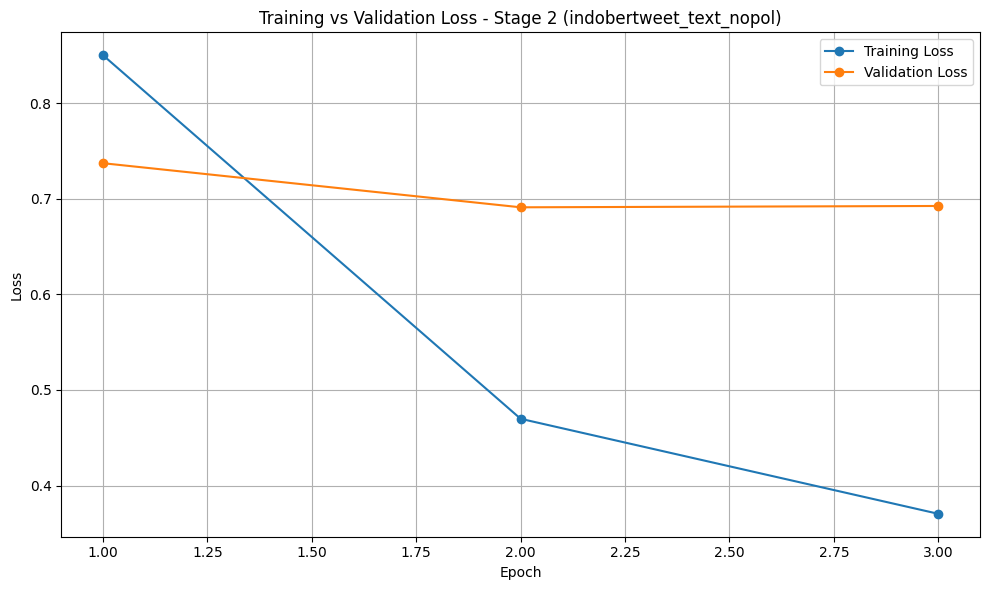

Stage 2 classification report -- test set (seed 42):
                               precision    recall  f1-score   support

                      insults       0.57      0.64      0.60       211
              identity_attack       0.56      0.59      0.58       199
threat_incitement_to_violence       0.25      0.18      0.21        22
          profanity_obscenity       0.54      0.62      0.58        72
            sexually_explicit       0.62      0.42      0.50        12

                    micro avg       0.56      0.59      0.57       516
                    macro avg       0.51      0.49      0.49       516
                 weighted avg       0.55      0.59      0.57       516
                  samples avg       0.49      0.50      0.47       516



,Label,TN,FP,FN,TP
0,insults,169,100,77,134
1,identity_attack,189,92,81,118
2,threat_incitement_to_violence,446,12,18,4
3,profanity_obscenity,370,38,27,45
4,sexually_explicit,465,3,7,5


In [33]:
plot_loss(trainer_s2, f"Training vs Validation Loss - Stage 2 ({RUN_TAG})")

print(f"Stage 2 classification report -- test set (seed {FINAL_SEEDS[-1]}):")
print(classification_report(y2_true, pred_label2, target_names=LABEL_COLS, zero_division=0))

cm_results = []
for i, label in enumerate(LABEL_COLS):
    tn, fp, fn, tp = confusion_matrix(y2_true[:, i], pred_label2[:, i], labels=[0, 1]).ravel()
    cm_results.append({"Label": label, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
pd.DataFrame(cm_results)

# Simpan Output

In [34]:
for d in [globals().get("FINAL_DIR"), globals().get("FINAL_DIR_S2")]:   # aman kalau satu stage dilewati
    if d and os.path.isdir(d):
        shutil.make_archive(f"{OUT_DIR}/{os.path.basename(d)}", "zip", root_dir=".", base_dir=d)
        print("ZIP berhasil dibuat:", f"{OUT_DIR}/{os.path.basename(d)}.zip")
print("File prediksi untuk 99_compare.ipynb:")
for f in sorted(os.listdir(OUT_DIR)):
    if f.startswith(f"preds_{RUN_TAG}"):
        print("  ", f)

ZIP berhasil dibuat: /kaggle/working/best_s1_indobertweet_text_nopol.zip
ZIP berhasil dibuat: /kaggle/working/best_s2_indobertweet_text_nopol.zip
File prediksi untuk 99_compare.ipynb:
   preds_indobertweet_text_nopol_s1.csv
   preds_indobertweet_text_nopol_s2.csv
